# Hedonic Pricing

We often try to predict the price of an asset from its observable characteristics. This is generally called **hedonic pricing**: How do the unit's characteristics determine its market price?

1. Clean the data `pierce_county_house_sales.csv` and perform some EDA and visualization to get to know the data set.
2. Transform your variables - particularly categorical ones - for use in your regression analysis.
3. Implement an 80/20 train-test split. Put the test data aside.
4. Build some simple linear models that include no transformations or interactions. Fit them, and determine their RMSE and $R^2$ on the both the training and test sets. Which of your models does the best?
5. Make partial correlation plots for each of the numeric variables in your model. Do you notice any significant non-linearities? 
6. Include transformations and interactions of your variables, and build a more complex model that reflects your ideas about how the features of the asset determine its value. Determine its RMSE and $R^2$ on the training and test sets. How does the more complex model your build compare to the simpler ones?
7. Summarize your results from 1 to 6. Have you learned anything about overfitting and underfitting, or model selection?
8. Use the `sklearn.linear_model.Lasso` to regularize your model and select the most predictive features. Which does it select? What are the RMSE and $R^2$? We'll cover the Lasso later in detail in class.

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** Maya D, Marilyn R, Jiei O

**Date:** 11/9

In [ ]:
# Your Phase 1 solution to the problem goes here.
print("Q1")
import numpy as np
import pandas as pd

df = pd.read_csv("data/pierce_county_house_sales.csv")
print(df.isna().sum())
df.describe()
df = df.drop_duplicates()
df = df.fillna({"waterfront_type": "None", "view_quality": "None"}) 
df =df.dropna()
df = df[(df["sale_price"] >= 50000) & (df["house_square_feet"] >= 300) &
        (df["bedrooms"].between(1, 10)) & (df["bathrooms"] >= 1)]
df["age"] = 2020 -df["year_built"]
df["sale_month"] = pd.to_datetime(df["sale_date"]).dt.month
df = df.drop(columns=["sale_date", "year_built", "interior", "utility_sewer"])
print(df.shape)
df.head()




sale_date                          0
sale_price                         0
house_square_feet                  0
attic_finished_square_feet         0
basement_square_feet               0
attached_garage_square_feet        0
detached_garage_square_feet        0
fireplaces                         0
hvac_description                   7
exterior                           1
interior                           7
stories                            0
roof_cover                         8
year_built                         0
bedrooms                           0
bathrooms                          0
waterfront_type                16261
view_quality                   15895
utility_sewer                      0
dtype: int64
(16663, 17)


,sale_price,house_square_feet,attic_finished_square_feet,basement_square_feet,attached_garage_square_feet,detached_garage_square_feet,fireplaces,hvac_description,exterior,stories,roof_cover,bedrooms,bathrooms,waterfront_type,view_quality,age,sale_month
0,380000,2157,0,0,528,0,0,Warm and Cool Air Zone,Frame Siding,2,Composition Shingle,3,3,None,None,27,1
1,383000,2238,0,0,396,0,0,Forced Air,Frame Siding,2,Composition Shingle,4,3,None,None,3,1
2,419900,1452,0,0,0,0,1,Forced Air,Frame Siding,1,Built Up Rock,3,2,None,None,55,1
3,251660,832,0,0,0,0,0,Forced Air,Frame Vinyl,1,Composition Shingle,2,1,None,None,101,1
4,500000,1780,0,384,484,0,1,Forced Air,Frame Siding,1,Composition Shingle,3,2,None,None,65,1


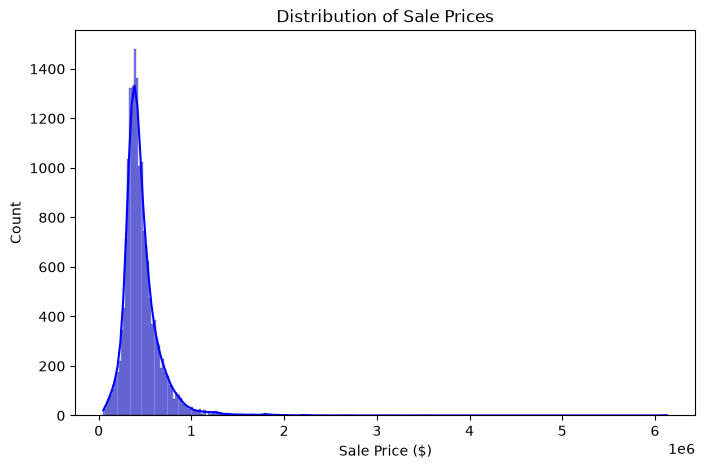

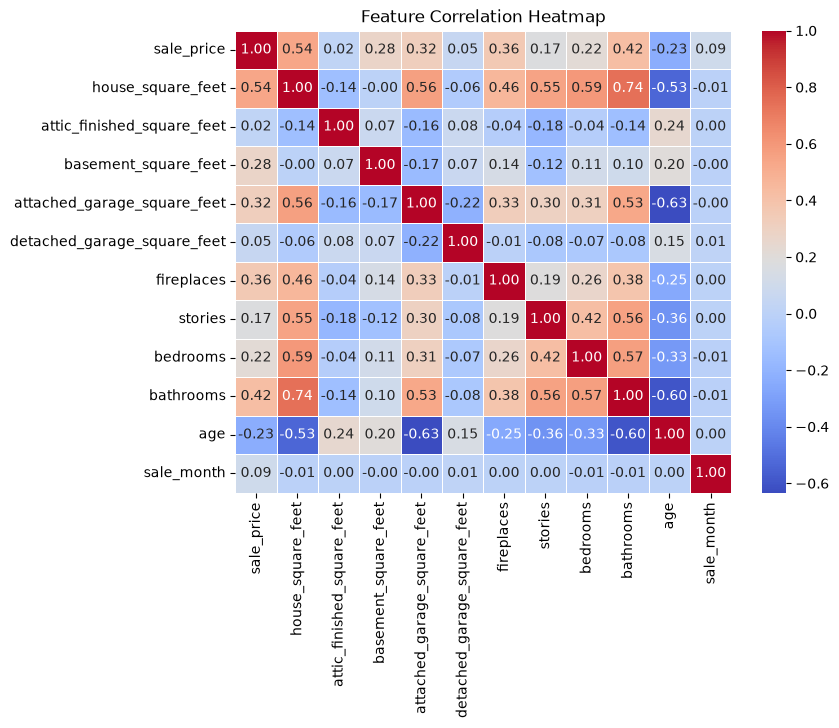

C:\Users\mnros\AppData\Local\Temp\ipykernel_4916\1822641361.py:19: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x="bedrooms", y="sale_price", palette="Set2")


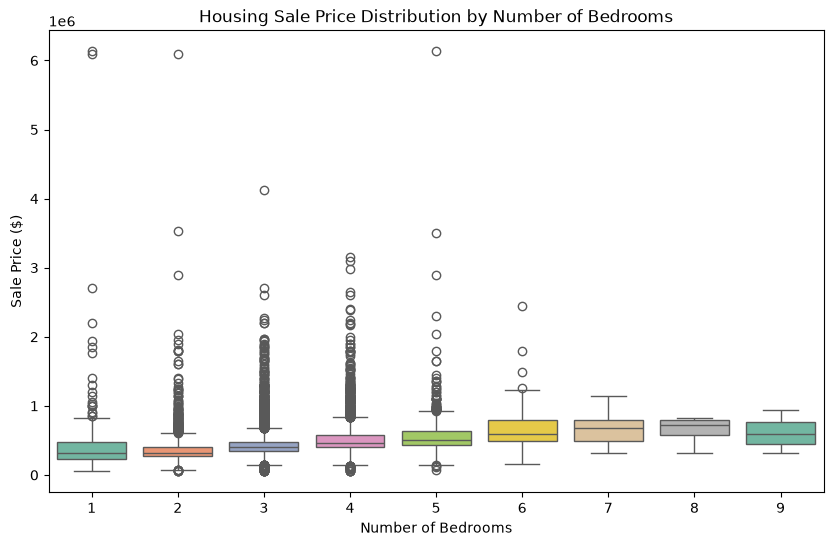

statistics
The mean of the sale price is:  461675.2796615255
The median of the sale price is:  417000.0
The IQR of the sale price is:  174921.0
The 25th percentile of the sale price is:  349000.0
The 75th percentile of the sale price is:  523921.0


In [47]:
import matplotlib.pyplot as plt
import seaborn as sns
plt.figure(figsize=(8, 5))
sns.histplot(data=df, x="sale_price", kde=True, color="blue")
plt.title("Distribution of Sale Prices")
plt.xlabel("Sale Price ($)")
plt.ylabel("Count")
plt.show()

plt.figure(figsize=(8, 6))
correlation_matrix = df.corr(numeric_only=True) 
sns.heatmap(correlation_matrix, annot=True, cmap="coolwarm", fmt=".2f", linewidths=0.5)
plt.title("Feature Correlation Heatmap")
plt.show()

plt.figure(figsize=(10, 6))

# Ensure bedrooms is treated as a category so it groups cleanly on the X-axis
sns.boxplot(data=df, x="bedrooms", y="sale_price", palette="Set2")

plt.title("Housing Sale Price Distribution by Number of Bedrooms")
plt.xlabel("Number of Bedrooms")
plt.ylabel("Sale Price ($)")
plt.show()

print("statistics")
print('The mean of the sale price is: ', df['sale_price'].mean())
print('The median of the sale price is: ', df['sale_price'].median())
print('The IQR of the sale price is: ', df['sale_price'].quantile(0.75) - df['sale_price'].quantile(0.25))
print('The 25th percentile of the sale price is: ', df['sale_price'].quantile(0.25))
print('The 75th percentile of the sale price is: ', df['sale_price'].quantile(0.75))


## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** [To be provided]
- **AI tool and model used:** [To be provided]

### *Prompts used

1. [Paste prompt]
2. [Paste follow-up prompt]

### *AI-proposed changes


[Paste the AI's concise numbered list verbatim.]

1. ...
2. ...

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | Accept / modify / reject | ... |
| 2 | Accept / modify / reject | ... |

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

In [ ]:
# Your Phase 2 solution to the problem goes here.


### *Reflection on AI assistance
In your own words without generative AI.

[In 150–300 words, describe the main improvements, AI mistakes or limitations, how the final solution was verified, and any remaining concerns.]